# 02. 긴 표 학습과 추론 전처리, 그리고 여기서 정한 것

[01 노트북](01_architecture_changes.ipynb)은 모델 안에서 바뀐 네 가지를 봤습니다. 2.5 논문은 모델 밖에서도 두 가지를 바꿨다고 적었습니다. 하나는 학습 데이터입니다. prior를 "more data points and more features"로 키웠고, 추론 권장 크기는 행 50,000개, feature 2,000개입니다. 다른 하나는 추론 때 앙상블 멤버의 전처리입니다. robust scaling과 soft clipping을 새로 넣었습니다.

논문은 두 가지 모두 세부를 거의 공개하지 않았습니다. prior 생성 방식, 학습 표 크기, 학습 step 수가 다 빠져 있습니다. 그래서 이 노트북은 논문이 적은 것과 이 저장소가 정한 것을 나눠 보고, 마지막 절에 2.5 재현에서 여기서 정한 것을 모두 모읍니다.

다루는 흐름:

1. 2.5가 겨냥하는 표 크기
2. 짧은 표로 오래, 긴 표로 잠깐 — `long_tables`
3. 학습 행 수: 균등 대신 log 균등
4. 셀 상한이 feature 수를 정한다
5. 처음부터가 아니라 이어서 학습하는 이유
6. 추론 전처리: robust scaling + soft clipping
7. 어떻게 돌리나
8. 논문에 없어서 여기서 정한 것

## `minipfn` 불러오기

01 노트북과 같은 import shim입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import json
import os
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.preprocessing import PowerTransformer

from minipfn import set_seed
from minipfn.inference.ensemble import EnsembleClassifier, EnsembleRegressor
from minipfn.inference.preprocessing import SOFT_CLIP, RobustSoftClip
from minipfn.models.cell_transformer import CellTransformer, CellTransformerConfig
from minipfn.priors.table_size import sample_table_size
from minipfn.recipes.tabpfn_v2 import default_inference, long_tables, paper, resolve_member_kinds, with_architecture

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 2.5가 겨냥하는 표 크기

논문 Table 1은 버전마다 권장하는 최대 표 크기를 적었습니다("Max Rows and Features are the recommended maximum sizes").

| 모델 | 행 | feature | 층 수 |
|---|---|---|---|
| TabPFN v1 | 1,000 | 100 | 8 |
| TabPFN v2 | 10,000 | 500 | 12 |
| TabPFN-2.5 | 50,000 | 2,000 | 18~24 |

v2 논문은 학습 표의 크기를 Methods에 적었습니다. 학습 행은 최대 2,048개, feature는 최대 160개이고, 표 하나의 셀은 75,000개까지입니다. 학습 때 본 것보다 큰 표(행 10,000개, feature 500개)에서도 동작하는 것은 01 노트북과 v2 primer에서 본 구조 덕분입니다. 2.5 논문은 학습 표의 크기를 적지 않았고, "scaled up to more data points and more features, while keeping the prediction tasks difficult"라고만 했습니다.

## 2. 짧은 표로 오래, 긴 표로 잠깐 — `long_tables`

이 저장소는 학습을 두 단계로 나눴습니다. 먼저 v2와 같은 크기의 표로 오래 학습하고(`paper`), 그 가중치를 가져와 더 긴·넓은 표로 짧게 이어 학습합니다(`long_tables`). TabICL이 짧은 표로 학습한 뒤 긴 표로 넘어가는 단계별 학습을 쓴 것을 따랐습니다. 2.5 논문에 없는 방식이고, 값도 여기서 정했습니다. 두 설정을 2.5 분류 구조로 나란히 놓습니다.

In [3]:
first = with_architecture(paper("classification"), "v2.5")
second = long_tables("classification", arch="v2.5")

fields = {
    "min_train_rows": "학습 행 수 하한",
    "max_train_rows": "학습 행 수 상한",
    "log_uniform_rows": "학습 행 수를 log 균등으로",
    "n_eval_rows": "정답을 가린 행 수",
    "feature_scale": "feature 수 분포를 펼 최대값",
    "max_features": "feature 수 상한",
    "max_cells": "표 하나의 셀 수 상한",
    "batch_size": "batch (데이터셋 수)",
    "micro_batch": "GPU당 micro batch",
    "steps": "학습률 스케줄 길이 (step)",
    "warmup_steps": "warmup (step)",
    "lr": "학습률",
    "qk_clip": "QK-clip",
}
display(
    pd.DataFrame(
        {
            "뜻": fields.values(),
            "paper (1단계)": [str(getattr(first, k)) for k in fields],  # None은 끈 것
            "long_tables (2단계)": [str(getattr(second, k)) for k in fields],
        },
        index=fields.keys(),
    )
)

,뜻,paper (1단계),long_tables (2단계)
min_train_rows,학습 행 수 하한,1,512
max_train_rows,학습 행 수 상한,2048,8192
log_uniform_rows,학습 행 수를 log 균등으로,False,True
n_eval_rows,정답을 가린 행 수,128,128
feature_scale,feature 수 분포를 펼 최대값,160,500
max_features,feature 수 상한,160,500
max_cells,표 하나의 셀 수 상한,75000,400000
batch_size,batch (데이터셋 수),64,64
micro_batch,GPU당 micro batch,8,1
steps,학습률 스케줄 길이 (step),2000000,20000


2단계는 학습 행을 512~8,192개, feature를 최대 500개로 넓히고, 셀 상한을 75,000개에서 400,000개로 올립니다. 이미 학습한 모델을 다듬는 단계라 학습률은 5e-5로 낮추고 step도 20,000으로 짧습니다. GPU당 micro batch가 1인 것은 메모리 때문입니다. v2(12층)는 이 크기에서 micro batch 2일 때 GPU 메모리를 52.6 GB 썼고, 2.5 분류는 층이 두 배라 1로 줄였습니다(`LONG_TABLES_MICRO_BATCH`). QK-clip은 분류에서 끄고(`None`), 회귀는 1단계와 2단계 모두 250을 씁니다.

1단계의 학습 step 수는 v2 설정의 기본값(스케줄 2,000,000 step)이 적혀 있지만, 실제로 몇 step까지 학습할지는 GPU 실측 뒤에 정합니다. v2는 100k step씩 끊어 이어 학습했습니다.

## 3. 학습 행 수: 균등 대신 log 균등

1단계는 학습 행 수를 1~2,048에서 균등하게 뽑습니다. 2단계는 512~8,192에서 log 균등으로 뽑습니다. 둘의 차이를 구간별 확률로 보면 다음과 같습니다. 512~8,192 범위를 두 배씩 네 구간으로 나눕니다.

In [4]:
low, high = 512, 8192
edges = [512, 1024, 2048, 4096, 8192]
probability = {}
for a, b in zip(edges[:-1], edges[1:]):
    probability[f"{a:,} ~ {b:,}"] = {
        "균등": (b - a) / (high - low),  # 구간 길이에 비례
        "log 균등": (np.log(b) - np.log(a)) / (np.log(high) - np.log(low)),  # log 길이에 비례
    }
display(pd.DataFrame(probability).T.rename_axis("학습 행 수").round(3))

,균등,log 균등
학습 행 수,,
"512 ~ 1,024",0.067,0.25
"1,024 ~ 2,048",0.133,0.25
"2,048 ~ 4,096",0.267,0.25
"4,096 ~ 8,192",0.533,0.25


균등하게 뽑으면 절반 넘게(53%) 4,096개 이상의 긴 표가 나옵니다. log 균등이면 네 구간이 25%씩입니다. 2단계에서도 짧은 표를 계속 보게 해서, 1단계에서 배운 짧은 표 성능을 잊지 않으면서 긴 표에 적응하게 하려는 것입니다.

실제 표 크기 규칙(`minipfn.priors.table_size.sample_table_size`)으로 20,000개씩 뽑아 두 설정을 비교합니다.

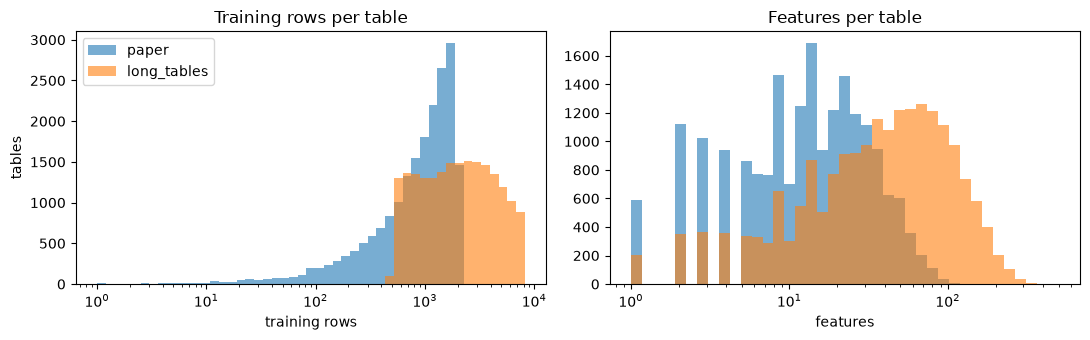

5%   중앙값   95%
paper       학습 행 수     104  1008  1935
            feature 수    2    13    49
long_tables 학습 행 수     590  1978  6656
            feature 수    4    40   152

In [5]:
def sample_sizes(config, n=20_000, seed=0):
    rng = np.random.default_rng(seed)
    sizes = [
        sample_table_size(
            rng,
            config.max_train_rows,
            config.n_eval_rows,
            config.max_features,
            min_train_rows=config.min_train_rows,
            log_uniform_rows=config.log_uniform_rows,
            max_cells=config.max_cells,
            feature_scale=config.feature_scale,
        )
        for _ in range(n)
    ]
    return np.array(sizes)  # (n, 2): 학습 행 수, feature 수


sizes = {"paper": sample_sizes(first), "long_tables": sample_sizes(second)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, s in sizes.items():
    axes[0].hist(s[:, 0], bins=np.geomspace(1, 8192, 50), alpha=0.6, label=name)
    axes[1].hist(s[:, 1], bins=np.geomspace(1, 500, 40), alpha=0.6, label=name)
axes[0].set(xscale="log", xlabel="training rows", ylabel="tables", title="Training rows per table")
axes[1].set(xscale="log", xlabel="features", title="Features per table")
axes[0].legend()
plt.tight_layout()
plt.show()

summary = {}
for name, s in sizes.items():
    for col, label in [(0, "학습 행 수"), (1, "feature 수")]:
        summary[(name, label)] = np.percentile(s[:, col], [5, 50, 95])
display(pd.DataFrame(summary, index=["5%", "중앙값", "95%"]).T.round(0).astype(int))

2단계에서 학습 행 수의 중앙값은 1,008개에서 1,978개로, feature 수의 중앙값은 13개에서 40개로 늘어납니다. long_tables의 학습 행 수가 log 균등인데도 4,000개 위에서 줄어드는 것은, 4절의 셀 상한이 feature가 많은 표의 학습 행 수를 줄이기 때문입니다. feature 수 분포는 v2와 같은 Beta(0.95, 8)을 [1, `feature_scale`]로 편 것이라, `feature_scale`을 160에서 500으로 올리면 모양은 같고 폭만 넓어집니다.

## 4. 셀 상한이 feature 수를 정한다

표 하나의 셀 수(정답을 가린 행 128개까지 포함)에 상한이 있어서, 행이 많은 표는 feature가 적어야 합니다. 학습 행 수별로 허용되는 feature 수 상한을 손으로 계산하면 다음과 같습니다.

In [6]:
cap_rows = {}
for n_train in [512, 2048, 4096, 8192]:
    rows_with_eval = n_train + 128  # 정답을 가린 행까지
    cap_rows[f"{n_train:,}"] = {
        "paper (셀 75,000)": 75_000 // rows_with_eval if n_train <= first.max_train_rows else "—",
        "long_tables (셀 400,000)": min(400_000 // rows_with_eval, second.max_features),
    }
display(pd.DataFrame(cap_rows).T.rename_axis("학습 행 수"))

,"paper (셀 75,000)","long_tables (셀 400,000)"
학습 행 수,,
512,117,500
"2,048",34,183
"4,096",—,94
"8,192",—,48


1단계는 학습 행이 2,048개면 feature가 34개까지입니다. 2단계는 같은 행 수에서 183개, 행이 8,192개면 48개까지입니다. 그래서 2단계도 "행 8,192개 × feature 500개" 같은 표는 만들지 않습니다. 긴 표는 좁게, 넓은 표는 짧게 나옵니다. 표 크기 규칙은 feature 수를 먼저 뽑고, 셀 상한에 맞춰 학습 행 수를 줄입니다.

## 5. 처음부터가 아니라 이어서 학습하는 이유

긴 표는 계산이 많이 듭니다. sample attention은 열마다 행 $R$개가 서로를 보므로 $R^2$에 비례하고, 열(토큰) 수 $C$만큼 반복됩니다. 3절에서 뽑은 표로 셀 수와 sample attention 계산량 $C \cdot R^2$의 평균을 비교합니다. $R$에는 정답을 가린 행 128개와 thinking 행 64개를 더하고, $C$는 셀 3개 묶음 수에 y 토큰 하나를 더한 것입니다.

In [7]:
cost = {}
for name, s in sizes.items():
    n_train, n_features = s[:, 0], s[:, 1]
    rows = n_train + 128 + 64  # 학습 + 정답을 가린 행 + thinking 행
    tokens = -(-n_features // 3) + 1  # 셀 3개 묶음 + y 토큰
    cost[name] = {
        "셀 수 평균": ((n_train + 128) * n_features).mean(),
        "sample attention C·R² 평균": (tokens * rows.astype(float) ** 2).mean(),
    }
cost_table = pd.DataFrame(cost).T
cost_table.loc["비율 (long_tables / paper)"] = cost_table.loc["long_tables"] / cost_table.loc["paper"]
display(cost_table.style.format("{:,.1f}"))

,셀 수 평균,sample attention C·R² 평균
paper,"19,817.1","12,450,488.0"
long_tables,"130,536.4","172,060,890.4"
비율 (long_tables / paper),6.6,13.8


2단계 표는 셀이 평균 6.6배, sample attention 계산이 14배 많습니다. 2단계 크기로 처음부터 오래 학습하면 같은 GPU 시간에 훨씬 적은 표밖에 보지 못합니다. 그래서 대부분의 학습은 싼 1단계에서 하고, 2단계는 짧게 붙입니다.

2단계를 시작하는 방식도 정했습니다. 1단계 run의 checkpoint에서 가중치만 가져오고(`--init-run-id`), optimizer 상태와 학습률 스케줄은 새로 시작합니다(warmup 1,000 step, 그다음 cosine으로 20,000 step까지). 모델 구조는 그대로라 1단계와 같은 클래스·같은 state_dict입니다.

## 6. 추론 전처리: robust scaling + soft clipping

추론할 때는 같은 표를 여러 방식으로 전처리해 모델에 넣고(앙상블 멤버), 예측을 평균합니다. v2 멤버의 전처리는 두 종류였습니다. 하나는 분위수 변환(quantile)이고 SVD 성분을 덧붙입니다. 다른 하나는 Yeo-Johnson power transform입니다. 2.5 논문은 "we combine robust scaling and soft clipping [RealMLP] with quantile transformations and standard scaling"이라고 적었고, 그 목적을 "robustness against outlier-prone feature distributions"라고 했습니다.

### 6.1 문제: 튀는 값 하나가 나머지를 뭉갠다

모델은 열마다 학습 행의 평균·표준편차로 z-정규화합니다(01 노트북 3절). 튀는 값이 하나 있으면 평균과 표준편차가 그 값에 끌려가서, 나머지 값들이 0 근처로 뭉칩니다. 8일 동안의 하루 걸음 수로 봅니다. 마지막 날은 마라톤을 뛴 날입니다.

In [8]:
steps = np.array([6200, 7100, 6800, 7500, 5900, 8100, 6600, 42000], dtype=float)
days = [f"{i + 1}일" for i in range(7)] + ["8일 (마라톤)"]


def model_z(values):
    # 모델 안의 z-정규화: 학습 행의 평균·표준편차 (n으로 나눔)
    return (values - values.mean()) / values.std()


steps_table = pd.DataFrame({"걸음 수": steps, "z-정규화": model_z(steps)}, index=days)
display(steps_table.round(2))
print(f"평범한 7일의 z 값 범위: {steps_table['z-정규화'][:7].min():.2f} ~ {steps_table['z-정규화'][:7].max():.2f}")

,걸음 수,z-정규화
1일,6200.0,-0.44
2일,7100.0,-0.36
3일,6800.0,-0.38
4일,7500.0,-0.32
5일,5900.0,-0.46
6일,8100.0,-0.27
7일,6600.0,-0.40
8일 (마라톤),42000.0,2.64


평범한 7일의 z 값 범위: -0.46 ~ -0.27


평범한 7일은 5,900보에서 8,100보까지 2,200보나 차이가 나는데, z 값으로는 $-0.46$에서 $-0.27$ 사이에 몰립니다. 모델 입장에서는 7일이 거의 같은 값으로 보입니다.

### 6.2 robust scaling + soft clipping을 손으로

robust scaling은 평균·표준편차 대신 튀는 값에 덜 흔들리는 통계를 씁니다. 중앙값을 빼고 사분위 폭(3사분위 − 1사분위)으로 나눕니다. 사분위 폭이 0이면(대부분 같은 값인 열) 2 / (최대 − 최소)를 곱합니다.

$$z = \frac{x - \text{중앙값}}{Q_3 - Q_1}$$

soft clipping은 그 결과를 $\pm 3$ 안으로 부드럽게 눌러 줍니다. 0 근처에서는 거의 그대로이고, 멀어질수록 3에 가까워지지만 넘지는 않습니다.

$$\text{soft clip}(z) = \frac{z}{\sqrt{1 + (z/3)^2}}$$

걸음 수에 단계별로 적용합니다.

In [9]:
q1, median, q3 = np.quantile(steps, [0.25, 0.5, 0.75])
print(f"중앙값 {median:,.0f}, 1사분위 {q1:,.0f}, 3사분위 {q3:,.0f}, 사분위 폭 {q3 - q1:,.0f}")

robust_z = (steps - median) / (q3 - q1)  # 1단계: robust scaling
clipped = robust_z / np.sqrt(1 + (robust_z / SOFT_CLIP) ** 2)  # 2단계: soft clipping (폭 3)

steps_table["robust scaling"] = robust_z
steps_table["+ soft clipping"] = clipped
steps_table["그다음 모델의 z-정규화"] = model_z(clipped)
display(steps_table.round(2))

same = np.allclose(RobustSoftClip().fit(steps[:, None]).transform(steps[:, None]).ravel(), clipped)
print("minipfn의 RobustSoftClip과 같음:", same)

중앙값 6,950, 1사분위 6,500, 3사분위 7,650, 사분위 폭 1,150


,걸음 수,z-정규화,robust scaling,+ soft clipping,그다음 모델의 z-정규화
1일,6200.0,-0.44,-0.65,-0.64,-0.84
2일,7100.0,-0.36,0.13,0.13,-0.17
3일,6800.0,-0.38,-0.13,-0.13,-0.40
4일,7500.0,-0.32,0.48,0.47,0.13
5일,5900.0,-0.46,-0.91,-0.87,-1.05
6일,8100.0,-0.27,1.00,0.95,0.55
7일,6600.0,-0.40,-0.30,-0.30,-0.55
8일 (마라톤),42000.0,2.64,30.48,2.99,2.32


minipfn의 RobustSoftClip과 같음: True


robust scaling만 해도 평범한 7일이 $-0.91$에서 $1.00$까지 퍼집니다. 마라톤 날은 30.5로 아주 크지만, soft clipping을 거치면 2.99로 눌립니다. 평범한 7일은 soft clipping을 거의 그대로 지나갑니다. 그 결과를 모델이 다시 z-정규화해도 7일의 차이가 살아 있습니다.

soft clipping 곡선을 그대로 쓰는 것($z$)과 $\pm 3$에서 딱 자르는 것(hard clip)과 함께 그려 봅니다.

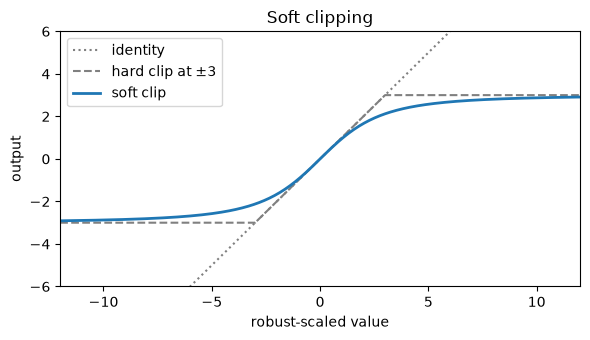

In [10]:
grid = np.linspace(-12, 12, 401)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid, grid, color="gray", linestyle=":", label="identity")
ax.plot(grid, np.clip(grid, -SOFT_CLIP, SOFT_CLIP), color="gray", linestyle="--", label="hard clip at ±3")
ax.plot(grid, grid / np.sqrt(1 + (grid / SOFT_CLIP) ** 2), linewidth=2, label="soft clip")
ax.set(xlim=(-12, 12), ylim=(-6, 6), xlabel="robust-scaled value", ylabel="output", title="Soft clipping")
ax.legend()
plt.tight_layout()
plt.show()

hard clip은 3을 넘는 값을 모두 3으로 만들어, 5와 10을 구분하지 못합니다. soft clip은 순서를 유지합니다. 5는 2.57, 10은 2.87이 되어, 큰 값끼리도 여전히 구분됩니다.

### 6.3 power transform과 무엇이 다른가 — 학습 행 범위 밖의 값

v2의 power 멤버(Yeo-Johnson)도 학습 행만 보면 마라톤 날을 잘 눌러 줍니다. 차이는 테스트 행에 학습 행 범위 밖의 값이 올 때 나타납니다. Yeo-Johnson은 열마다 지수 $\lambda$를 학습 행에 맞추는데, $\lambda$가 0에서 멀면 범위 밖의 값을 아주 크게 키울 수 있습니다. 테스트 행 세 개를 넣어 봅니다: 평범한 날(7,000보), 비 온 날(2,000보), 아파서 누워 있던 날(0보).

In [11]:
test_steps = np.array([7000, 2000, 0], dtype=float)

power = PowerTransformer(method="yeo-johnson", standardize=True).fit(steps[:, None])
robust = RobustSoftClip().fit(steps[:, None])

print(f"학습 행에 맞춘 Yeo-Johnson λ = {power.lambdas_[0]:.2f}")
display(
    pd.DataFrame(
        {
            "걸음 수": test_steps,
            "power (v2 멤버)": power.transform(test_steps[:, None]).ravel(),
            "robust + soft clip (2.5 멤버)": robust.transform(test_steps[:, None]).ravel(),
        },
        index=["평범한 날", "비 온 날", "아파서 누운 날"],
    ).map(lambda v: f"{v:,.4g}")
)
print("학습 행 8개의 power 값 범위:", power.transform(steps[:, None]).min().round(2), "~", power.transform(steps[:, None]).max().round(2))

학습 행에 맞춘 Yeo-Johnson λ = -2.54


,걸음 수,power (v2 멤버),robust + soft clip (2.5 멤버)
평범한 날,"7,000",-0.1004,0.04347
비 온 날,"2,000",-52.67,-2.461
아파서 누운 날,0,-1.34e+10,-2.687


학습 행 8개의 power 값 범위: -1.34 ~ 2.15


학습 행에서 power 값은 $-1.34$에서 $2.15$ 사이였습니다. 그런데 $\lambda = -2.54$에서는 학습 행 최솟값(5,900)보다 작은 값이 급격히 커져서, 2,000보는 $-52.7$, 0보는 $-1.3 \times 10^{10}$이 됩니다. robust + soft clip은 무슨 값이 와도 $\pm 3$ 안입니다.

실제 추론에서는 power 변환 전에 학습 행 평균에서 표준편차 12배 밖의 값을 자르고(`OUTLIER_SIGMA`), 모델 안에서도 z 값을 $\pm 100$으로 자릅니다. 그래서 무한대가 모델에 들어가지는 않습니다. 하지만 모델이 학습 때 본 값(대부분 몇 이내)보다 훨씬 큰 값이 들어가는 것은 같습니다. 2.5 논문이 적은 "outlier-prone feature distributions"에 대한 robustness는 이런 경우를 말하는 것으로 읽었습니다.

### 6.4 멤버를 어떻게 섞나 (여기서 정한 것)

논문은 robust scaling + soft clipping을 "quantile transformations and standard scaling"과 함께 쓴다고만 적었고, Yeo-Johnson을 계속 쓰는지는 적지 않았습니다. 이 저장소는 다음처럼 정했습니다.

- 2.5 멤버 종류는 `("quantile", "robust")`입니다. v2의 `("quantile", "power")`에서 power 자리를 robust가 대신합니다.
- standard scaling은 모델 안의 z-정규화가 이미 하므로 따로 멤버를 두지 않습니다.
- SVD 성분은 v2처럼 quantile 멤버에만 붙입니다(논문: "in some of the estimators").
- robust 멤버에서 범주형 열은 power 멤버처럼 번호 그대로 둡니다.

어느 묶음을 쓸지는 가중치가 정합니다(`default_inference`). Hub의 `config.json`에 적힌 값이 있으면 그것을 쓰고, 없으면 모델 구조가 2.5이면 v2.5 묶음입니다. 실제 크기 모델로 확인합니다.

In [12]:
for arch in ["v2", "v2.5"]:
    for task in ["classification", "regression"]:
        model = with_architecture(paper(task), arch).build_model()
        print(f"{arch:4} {task:14} → {default_inference(model, task)}")

v2   classification → {'n_estimators': 4, 'member_kinds': ('quantile', 'power')}
v2   regression     → {'n_estimators': 8, 'member_kinds': ('quantile', 'power')}
v2.5 classification → {'n_estimators': 4, 'member_kinds': ('quantile', 'robust')}
v2.5 regression     → {'n_estimators': 8, 'member_kinds': ('quantile', 'robust')}


멤버 수는 v2 논문 기본값(분류 4개, 회귀 8개) 그대로이고, 멤버 종류를 차례로 돌려 씁니다. 회귀는 멤버 절반의 y에도 power transform을 겁니다. 작은 모델로 앙상블을 만들어 멤버마다 무엇을 하는지 꺼내 봅니다. 학습하지 않은 모델이라 예측은 보지 않고 멤버 구성만 봅니다. 입력은 feature 3개, 학습 행 30개짜리 무작위 표입니다.

In [13]:
rng = np.random.default_rng(0)
x_small = rng.normal(size=(30, 3))
y_class = rng.integers(0, 2, size=30)
y_value = x_small @ np.array([1.0, -0.5, 0.2]) + 0.1 * rng.normal(size=30)

tiny = CellTransformer(CellTransformerConfig(emsize=16, nlayers=1, nhead=2, features_per_group=3, n_thinking_rows=4, n_out=10))
borders = torch.linspace(-3, 3, 11)  # 구간 10개의 경계 (회귀 앙상블을 만들려면 필요하다)

member_rows = []
for kinds in ["v2", "v2.5"]:
    member_kinds = resolve_member_kinds(kinds)  # 묶음 이름 → 종류 목록, 예: "v2.5" → ("quantile", "robust")
    clf = EnsembleClassifier(tiny, n_estimators=4, member_kinds=member_kinds).fit(x_small, y_class)
    reg = EnsembleRegressor(tiny, borders, n_estimators=8, member_kinds=member_kinds).fit(x_small, y_value)
    for task, ens in [("분류", clf), ("회귀", reg)]:
        for i, (prep, x_member) in enumerate(zip(ens.preprocessors_, ens.X_trains_)):
            member_rows.append(
                {
                    "묶음": kinds,
                    "task": task,
                    "멤버": i + 1,
                    "전처리": prep.member.kind,
                    "y power (회귀)": prep.member.target_power if task == "회귀" else "—",
                    "모델 입력 열 수": x_member.shape[1],
                }
            )

members = pd.DataFrame(member_rows)
display(members[members["task"] == "분류"].set_index(["묶음", "멤버"]).drop(columns=["task", "y power (회귀)"]).unstack(0))
display(members[members["task"] == "회귀"].set_index(["묶음", "멤버"]).drop(columns="task").unstack(0))

전처리           모델 입력 열 수     
묶음        v2      v2.5        v2 v2.5
멤버                                   
1   quantile  quantile         8    8
2      power    robust         4    4
3   quantile  quantile         8    8
4      power    robust         4    4

전처리           y power (회귀)        모델 입력 열 수     
묶음        v2      v2.5           v2   v2.5        v2 v2.5
멤버                                                       
1   quantile  quantile        False  False         8    8
2      power    robust        False  False         4    4
3   quantile  quantile         True   True         8    8
4      power    robust         True   True         4    4
5   quantile  quantile        False  False         8    8
6      power    robust        False  False         4    4
7   quantile  quantile         True   True         8    8
8      power    robust         True   True         4    4

분류 멤버 4개는 quantile과 robust를 번갈아 씁니다. quantile 멤버는 원래 열 3개, 분위수 열 3개, SVD 성분 1개, 샘플 식별자 열 1개로 모델 입력이 8열이고, robust 멤버는 변환한 열 3개에 샘플 식별자 열 1개를 더한 4열입니다. 회귀 멤버 8개는 2개씩 y power를 껐다 켰다 하므로, 종류마다 정확히 절반이 y power 멤버입니다.

## 7. 어떻게 돌리나

학습과 평가는 v2와 같은 스크립트(`scripts/tabpfn_v2/{train,eval}.py`)이고, 2.5 설정을 고르는 AI Runtime yaml은 `scripts/tabpfn_v2_5/{train,eval}.yaml`에 있습니다. 명령은 저장소 루트에서 돌립니다. `$MLFLOW_EXPERIMENT_DIR`는 `.env.local`에 둔 experiment 폴더입니다.

1단계 전에 먼저 medium 설정으로 짧게 돌려 step 시간과 GPU 메모리를 잽니다(yaml 기본값: 8×H100, 2.5 분류, 300 step).

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR
```

1단계(paper)는 100k step씩 끊어 이어 학습합니다. 회귀는 `TABPFN_V2_TASK=regression`을 더합니다.

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_V2_CONFIG_NAME=paper --override env_variables.TABPFN_V2_STEPS=<전체 step> \
  --override env_variables.TABPFN_V2_STOP_STEP=<이번 chunk 끝> --override mlflow_run_name=tabpfn-v2-5-<task>-paper-chunkNN
# 이어서: --override env_variables.TABPFN_V2_RESUME_RUN_ID=<run_id>
```

2단계(long_tables)는 1단계 run의 가중치에서 시작합니다.

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_V2_CONFIG_NAME=long_tables \
  --override env_variables.TABPFN_V2_INIT_RUN_ID=<paper run_id> --override env_variables.TABPFN_V2_INIT_STEP=<step>
```

평가는 v2와 같은 benchmark(v2 논문 Supplementary Tables 1·2의 분류 29개, 회귀 28개)에서 100k step 단위 checkpoint로 합니다. 멤버 전처리는 yaml 기본값이 v2.5 묶음입니다.

```bash
databricks air run -f scripts/tabpfn_v2_5/eval.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override "env_variables.TABPFN_V2_EXTRA_ARGS=--suite classification --classifier-path runs:/<run_id>/checkpoints/step_0100000.pt"
```

로컬에서는 같은 학습 스크립트를 smoke 크기로 돌려 코드 경로를 확인할 수 있습니다. smoke는 층 수를 그대로 두고 thinking 행을 4개로 줄입니다. 2.5 회귀 구조로 20 step 돌립니다(CPU에서 30초 안팎).

In [14]:
repo = Path.cwd().parents[1]
env = {**os.environ, "PYTHONHASHSEED": "1", "MLFLOW_DISABLE_AGENT_HINT": "1", "PYTHONPATH": str(repo / "src")}
env.pop("MLFLOW_TRACKING_URI", None)  # 로컬 임시 폴더에 기록한다

with tempfile.TemporaryDirectory() as tmp:
    command = [
        sys.executable, str(repo / "scripts" / "tabpfn_v2" / "train.py"),
        "--config-name", "smoke", "--arch", "v2.5", "--task", "regression", "--out-dir", tmp,
    ]
    result = subprocess.run(command, cwd=tmp, env=env, capture_output=True, text=True, check=True)
    for line in result.stdout.splitlines():
        if line.startswith(("step", "  val", "regression borders")):
            print(line)
    saved = json.loads((Path(tmp) / "train_config.json").read_text())

keys = ["task", "nlayers", "features_per_group", "n_thinking_rows", "encoder", "emsize"]
display(pd.Series({k: saved[k] for k in keys}, name="smoke 설정").to_frame())

regression borders: 40 datasets, 6s
step 5/20 loss 2.0136 lr 9.33e-04 0.172s/step wait 91% skipped 0
step 10/20 loss 6.8609 lr 5.87e-04 0.238s/step wait 95% skipped 0
  val val_loss 15.4912
step 15/20 loss 1.6276 lr 1.79e-04 0.147s/step wait 84% skipped 0
step 20/20 loss 2.6816 lr 0.00e+00 0.257s/step wait 95% skipped 0
  val val_loss 15.4786


,smoke 설정
task,regression
nlayers,2
features_per_group,3
n_thinking_rows,4
encoder,mlp
emsize,32


## 8. 논문에 없어서 여기서 정한 것

2.5 논문은 구조 변경 네 가지를 문장 몇 개로 적었고, 학습 데이터와 학습 설정은 거의 공개하지 않았습니다. 이 저장소가 2.5를 재현하며 정한 것을 모두 모읍니다. 목표는 논문을 그대로 옮기는 것이 아니라, 공개된 정보로 학습해서 benchmark 숫자를 다시 내는 것입니다.

| 무엇 | 논문이 적은 것 | 여기서 정한 것 | 코드 |
|---|---|---|---|
| 임베딩 크기, head 수 | 적지 않음 | v2 그대로 192, 6 | `recipes/tabpfn_v2.py` `ARCHITECTURES` |
| thinking 행 | 64개, pretraining 때 학습, attention sink 역할 | 행마다 벡터 하나를 모든 열에 씀, 열 이름표는 더하지 않음, 학습 행 앞에 둬 key·value로 씀, 출력은 버림, 처음 값 0.02 × 표준정규 난수 | `models/cell_transformer.py` |
| 회귀 MLP encoder | 회귀의 linear encoder를 2층 MLP로 | feature 셀 묶음 encoder에 적용, Linear → GELU → Linear(hidden = E), y encoder는 linear 그대로 | `models/cell_transformer.py` |
| prior | "substantially" 개선, 더 많은 행·feature | v2 재현과 같은 TabICL graph SCM prior(`graph_scm`) | `priors/graph_scm.py` |
| 학습 설정 | 공개 안 됨 | v2 설정에서 시작: batch 64, lr 2e-4, warmup 10k. 회귀는 QK-clip 250, 붕괴로 되돌릴 때 lr × 0.5 | `recipes/tabpfn_v2.py` `paper` |
| 긴 표 학습 | 공개 안 됨 (추론 권장 크기만: 행 50,000, feature 2,000) | 2단계 `long_tables`: 학습 행 512~8,192 log 균등, feature 최대 500, 셀 400,000, 가중치만 가져와 lr 5e-5로 20k step, micro batch 1 | `recipes/tabpfn_v2.py` `long_tables` |
| 추론 멤버 | robust scaling + soft clipping(RealMLP)을 quantile·standard와 함께, 일부 멤버에 SVD | `("quantile", "robust")`: power 자리를 robust가 대신, standard는 모델 안 z-정규화, SVD는 quantile 멤버에만, robust 멤버의 범주형은 번호 그대로 | `recipes/tabpfn_v2.py` `MEMBER_KINDS_V2_5` |
| robust 세부 | 적지 않음 | 사분위 폭이 0이면 2 / (최대 − 최소), soft clip 폭 3 | `inference/preprocessing.py` `RobustSoftClip` |
| 실데이터 fine-tune (Real-TabPFN-2.5) | 실데이터 43개로 fine-tune | 하지 않음 | — |

v2 재현에서 정한 것(QK-clip, 붕괴 감지와 되돌리기, 회귀 평균 계산, one-hot 범주형 등)은 2.5에도 그대로 들어갑니다. 판정은 두 가지입니다. v2와 같은 benchmark(분류 29개, 회귀 28개)에서 v2보다 나은지, 그리고 TabArena-Lite에서 어디쯤인지입니다. 2.5 재현 결과는 학습이 끝난 뒤 이 폴더의 다음 노트북에 정리합니다.